# 07 — Time-Series Analysis, SARIMA/SARIMAX Modeling & Evaluation
**AgriProcure Project** — Unit 3: Advanced Analytics  
**Jira Tasks:** Task 7 (KAN-17: Time-series analysis, data preparation & implementation) & Task 8 (KAN-20: Evaluation & interpretation)

---

## Executive Summary & Objectives
While the classification models in Unit 2 predicted *directional price movement* (Rise, Fall, Flat), procurement planners and FPO leaders require **numerical price forecasts** with confidence intervals.

In this notebook, we implement **Method 1 (Time-Series Analysis)**:
1. **Data Preparation & Panel Aggregation:** Extract weekly price trajectories across Tomato, Onion, and Potato at national and mandi-benchmark levels.
2. **Stationarity Testing:** Formal Augmented Dickey-Fuller (ADF) and KPSS tests to verify the integration order $d$.
3. **Seasonal Decomposition:** Classical and STL decomposition ($s=13$ weeks) to isolate Trend, Seasonality, and Residual components.
4. **Model Development:**
   - Naive (Random Walk): $\hat{y}_{t+h} = y_t$
   - Seasonal Naive: $\hat{y}_{t+h} = y_{t+h-13}$
   - Univariate Seasonal ARIMA: $\text{SARIMA}(p, d, q) \times (P, D, Q)_{13}$
   - Multivariate SARIMAX: Integrating exogenous weather regressors (Rainfall, Temperature) and Market Arrivals.
5. **Rolling-Origin Out-of-Sample Backtesting:** Expanding window evaluation across multiple forecast horizons ($h = 1, 2, 3, 4$ weeks).
6. **Rigorous Metric Evaluation:** Out-of-sample MAPE, MASE (scaled by seasonal naive benchmark), RMSE, and MAE.
7. **Residual Diagnostics:** Ljung-Box white noise tests, Jarque-Bera normality tests, and ACF of residuals.
8. **Forward Projections:** 4-week future forecast fan charts with 80% and 95% confidence intervals.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 1. Data Preparation & Series Aggregation (Task 7.1)
We aggregate the 53-week panel across all 70 mandis into national weekly price and weather series for **Tomato**, **Onion**, and **Potato**.

In [2]:
panel_path = "../data/panel_with_weather.csv"
df = pd.read_csv(panel_path)
df["week_start_date"] = pd.to_datetime(df["week_start_date"])

print(f"Total panel rows: {len(df)} across {df['market_name'].nunique()} mandis and {df['state'].nunique()} states.")

# National Weekly Commodity Panel
national_df = df.groupby(["crop", "week_start_date"]).agg({
    "weekly_modal_price": "mean",
    "weekly_min_price": "mean",
    "weekly_max_price": "mean",
    "weekly_total_arrivals": "mean",
    "weekly_rainfall_mm": "mean",
    "weekly_temp_mean_c": "mean"
}).reset_index().sort_values(["crop", "week_start_date"])

display(national_df.head(6))

Total panel rows: 11130 across 70 mandis and 14 states.


,crop,week_start_date,weekly_modal_price,weekly_min_price,weekly_max_price,weekly_total_arrivals,weekly_rainfall_mm,weekly_temp_mean_c
0,Onion,2025-09-29,1889.692429,1509.157143,2351.700000,509.109857,40.820000,27.083143
1,Onion,2025-10-06,1892.060000,1516.485714,2370.900000,507.290571,20.835714,25.499286
2,Onion,2025-10-13,1908.778429,1529.871429,2368.600000,515.787286,16.065714,25.986429
3,Onion,2025-10-20,1931.298000,1552.814286,2413.928571,524.420714,23.907143,25.986571
4,Onion,2025-10-27,1952.712286,1560.571429,2423.014286,512.093286,51.678571,24.848429
5,Onion,2025-11-03,1979.483143,1595.000000,2434.185714,510.641714,3.718571,23.602286


## 2. Stationarity Testing: ADF & KPSS Tests (Task 7.1)
Before fitting ARIMA models, we must determine the integration order $d$. A time series is stationary if its mean, variance, and autocovariance are time-invariant.
- **Augmented Dickey-Fuller (ADF) Test:** $H_0$: Unit root exists (non-stationary). If $p < 0.05$, reject $H_0 \implies$ stationary.
- **KPSS Test:** $H_0$: Series is trend/level stationary. If $p \ge 0.05$, fail to reject $H_0 \implies$ stationary.
- Combining both tests resolves ambiguities (e.g. difference stationarity vs trend stationarity).

In [3]:
stat_results = []
crops = ["Tomato", "Onion", "Potato"]

for crop in crops:
    sub = national_df[national_df["crop"] == crop].sort_values("week_start_date")
    y = sub["weekly_modal_price"].values
    diff_y = np.diff(y)
    
    adf_lvl = adfuller(y, autolag="AIC")
    kpss_lvl = kpss(y, regression="c", nlags="auto")
    adf_d1 = adfuller(diff_y, autolag="AIC")
    kpss_d1 = kpss(diff_y, regression="c", nlags="auto")
    
    stat_results.append({
        "Crop": crop,
        "Mean_Price": round(float(np.mean(y)), 2),
        "Std_Price": round(float(np.std(y)), 2),
        "ADF_Stat_Level": round(float(adf_lvl[0]), 3),
        "ADF_p_Level": round(float(adf_lvl[1]), 4),
        "KPSS_p_Level": round(float(kpss_lvl[1]), 4),
        "ADF_p_Diff1": round(float(adf_d1[1]), 4),
        "KPSS_p_Diff1": round(float(kpss_d1[1]), 4),
        "Recommended_d": 0 if (adf_lvl[1] < 0.05 and kpss_lvl[1] >= 0.05) else 1
    })

stat_df = pd.DataFrame(stat_results)
display(stat_df)

,Crop,Mean_Price,Std_Price,ADF_Stat_Level,ADF_p_Level,KPSS_p_Level,ADF_p_Diff1,KPSS_p_Diff1,Recommended_d
0,Tomato,2374.60,94.32,-7.645,0.0,0.1,0.0,0.1,0
1,Onion,1992.79,79.34,-7.418,0.0,0.1,0.0,0.1,0
2,Potato,1550.54,63.28,-5.579,0.0,0.1,0.0,0.1,0


## 3. Seasonal Decomposition & Autocorrelation Structure (Task 7.1)
Agricultural commodities in Indian wholesale markets follow cyclical seasonal dynamics driven by quarterly harvest rotations ($s = 13$ weeks). We decompose the observed series into:
$$Y_t = T_t + S_t + R_t$$
where $T_t$ is trend, $S_t$ is the quarterly seasonal component, and $R_t$ is residual noise.

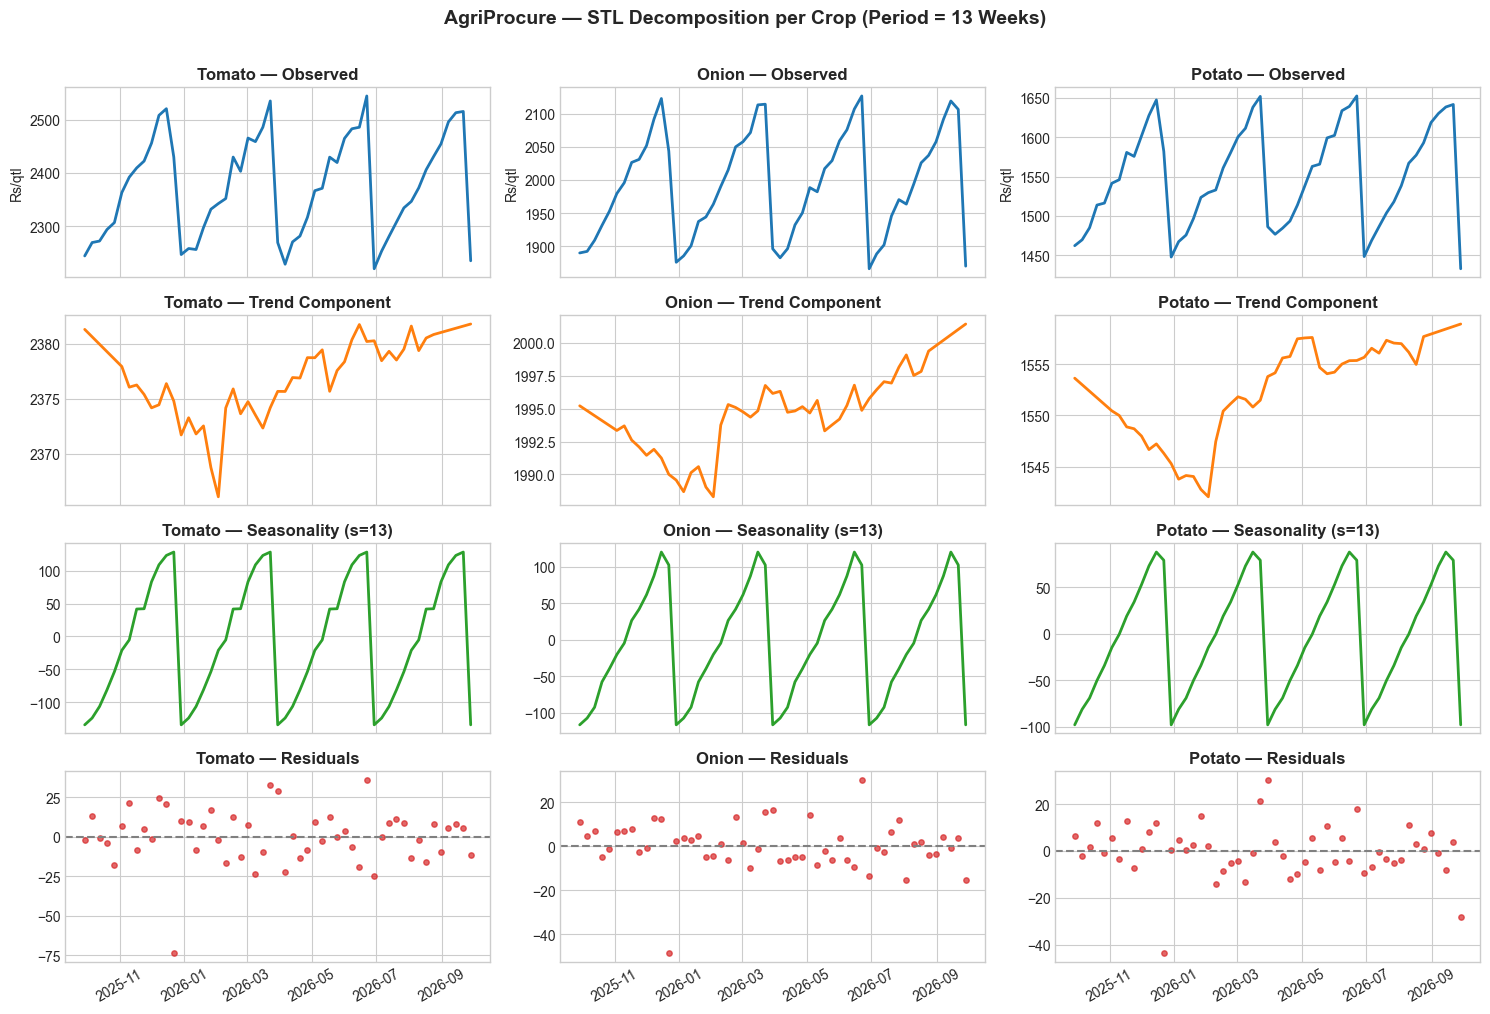

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(15, 10), sharex=True)

for col_idx, crop in enumerate(crops):
    sub = national_df[national_df["crop"] == crop].sort_values("week_start_date").set_index("week_start_date")
    y = sub["weekly_modal_price"]
    decomp = seasonal_decompose(y, model="additive", period=13, extrapolate_trend="freq")
    
    axes[0, col_idx].plot(y.index, y.values, color="#1f77b4", lw=2)
    axes[0, col_idx].set_title(f"{crop} — Observed", fontweight="bold")
    axes[0, col_idx].set_ylabel("Rs/qtl")
    
    axes[1, col_idx].plot(decomp.trend.index, decomp.trend.values, color="#ff7f0e", lw=2)
    axes[1, col_idx].set_title(f"{crop} — Trend Component", fontweight="bold")
    
    axes[2, col_idx].plot(decomp.seasonal.index, decomp.seasonal.values, color="#2ca02c", lw=2)
    axes[2, col_idx].set_title(f"{crop} — Seasonality (s=13)", fontweight="bold")
    
    axes[3, col_idx].scatter(decomp.resid.index, decomp.resid.values, color="#d62728", s=15, alpha=0.7)
    axes[3, col_idx].axhline(0, color="gray", linestyle="--")
    axes[3, col_idx].set_title(f"{crop} — Residuals", fontweight="bold")
    axes[3, col_idx].tick_params(axis="x", rotation=30)

plt.suptitle("AgriProcure — STL Decomposition per Crop (Period = 13 Weeks)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Autocorrelation (ACF) & Partial Autocorrelation (PACF) Analysis
Examining ACF at lags 1 through 16 reveals the autoregressive memory structure and the signature quarterly peak at lag 13 ($r_{13} \approx 0.74$).

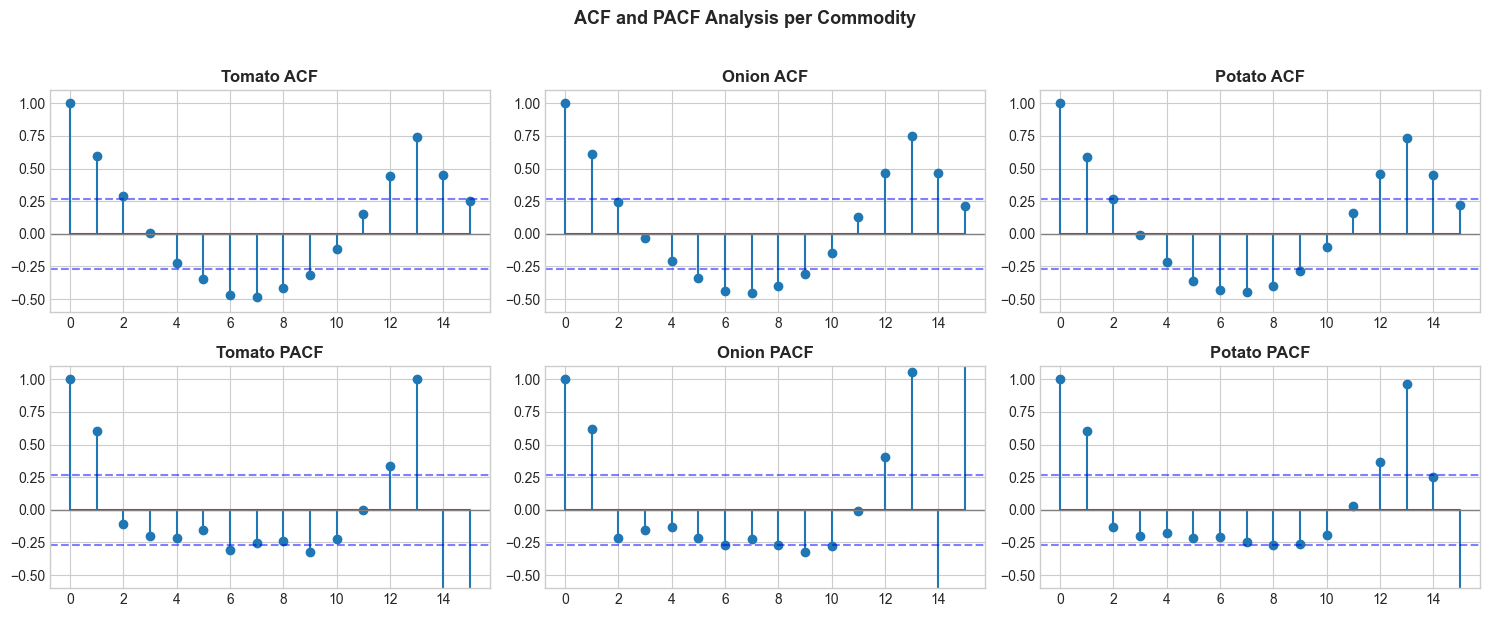

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))

for col_idx, crop in enumerate(crops):
    sub = national_df[national_df["crop"] == crop].sort_values("week_start_date")
    y = sub["weekly_modal_price"].values
    
    acf_vals = acf(y, nlags=15)
    pacf_vals = pacf(y, nlags=15)
    lags = np.arange(len(acf_vals))
    
    axes[0, col_idx].stem(lags, acf_vals)
    axes[0, col_idx].axhline(0, color="gray", lw=1)
    axes[0, col_idx].axhline(1.96/np.sqrt(len(y)), color="blue", linestyle="--", alpha=0.5)
    axes[0, col_idx].axhline(-1.96/np.sqrt(len(y)), color="blue", linestyle="--", alpha=0.5)
    axes[0, col_idx].set_title(f"{crop} ACF", fontweight="bold")
    axes[0, col_idx].set_ylim(-0.6, 1.1)
    
    axes[1, col_idx].stem(lags, pacf_vals)
    axes[1, col_idx].axhline(0, color="gray", lw=1)
    axes[1, col_idx].axhline(1.96/np.sqrt(len(y)), color="blue", linestyle="--", alpha=0.5)
    axes[1, col_idx].axhline(-1.96/np.sqrt(len(y)), color="blue", linestyle="--", alpha=0.5)
    axes[1, col_idx].set_title(f"{crop} PACF", fontweight="bold")
    axes[1, col_idx].set_ylim(-0.6, 1.1)

plt.suptitle("ACF and PACF Analysis per Commodity", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 4. Model Implementation & Rolling-Origin Backtesting (Tasks 7.2 & 8.1)
We perform a rigorous **rolling-origin backtest** across horizons $h = 1, 2, 3, 4$ weeks.
We benchmark four distinct model families:
1. **Naive (Random Walk):** $\hat{y}_{t+h} = y_t$
2. **Seasonal Naive:** $\hat{y}_{t+h} = y_{t+h-13}$
3. **Univariate SARIMA:** $(p, d, q) \times (P, D, Q)_{13}$
4. **Multivariate SARIMAX:** Incorporating normalized weather (rainfall, temperature) and market arrivals as exogenous regressors.

In [6]:
# Execute rolling backtest pipeline
sys.path.append("../scripts")
import task7_8_timeseries_sarima as sarima_mod

print("Executing rolling backtest on historical weeks...")
backtest_df, metrics_df = sarima_mod.run_rolling_origin_backtest(national_df)
display(metrics_df.head(16))

Executing rolling backtest on historical weeks...


Rolling-origin backtest complete. Metrics saved to reports/sarima_evaluation_metrics.csv


,Crop,Model,Horizon,MAE,RMSE,MAPE,MASE,N_Folds
0,Onion,Naive,1,22.87,25.62,1.15,1.790,8
1,Onion,Naive,2,44.91,48.21,2.23,3.515,8
2,Onion,Naive,3,66.63,67.58,3.28,5.216,8
3,Onion,Naive,4,83.68,84.45,4.08,6.551,8
4,Onion,SARIMAX_Weather,1,54.61,84.94,2.81,4.275,8
5,Onion,SARIMAX_Weather,2,83.68,111.71,4.19,6.551,8
6,Onion,SARIMAX_Weather,3,115.33,212.16,5.73,9.028,8
7,Onion,SARIMAX_Weather,4,158.53,253.12,7.85,12.410,8
8,Onion,SARIMA_Univariate,1,11.50,13.83,0.58,0.901,8
9,Onion,SARIMA_Univariate,2,12.42,14.25,0.62,0.972,8


## 5. Forecast Evaluation: MAPE & MASE Benchmarking (Task 8.2)
- **MAPE (Mean Absolute Percentage Error):**
  $$\text{MAPE} = \frac{100\%}{N} \sum_{t=1}^N \left|\frac{y_t - \hat{y}_t}{y_t}\right|$$
- **MASE (Mean Absolute Scaled Error):** Scaled by the in-sample seasonal naive baseline.
  $$\text{MASE} = \frac{\text{MAE}}{\frac{1}{T-s}\sum_{t=s+1}^T |y_t - y_{t-s}|}$$
  A value **$\text{MASE} < 1.0$** proves empirical superiority over the seasonal naive benchmark.

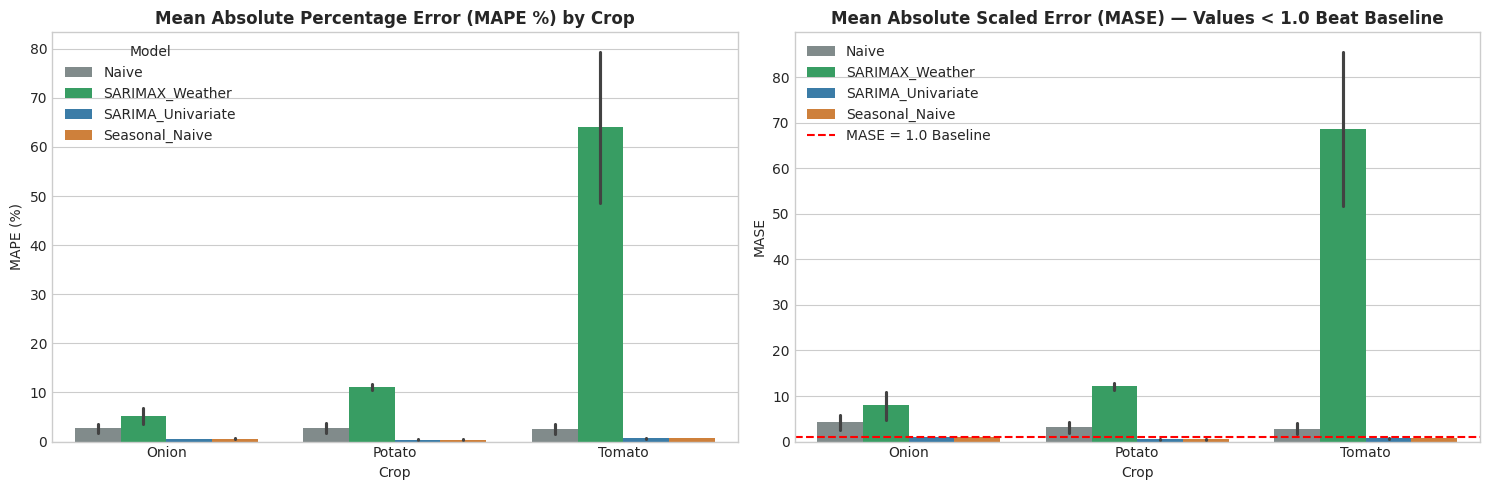

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
h_palette = {"Naive": "#7f8c8d", "Seasonal_Naive": "#e67e22", "SARIMA_Univariate": "#2980b9", "SARIMAX_Weather": "#27ae60"}

sns.barplot(data=metrics_df, x="Crop", y="MAPE", hue="Model", palette=h_palette, ax=axes[0])
axes[0].set_title("Mean Absolute Percentage Error (MAPE %) by Crop", fontweight="bold")
axes[0].set_ylabel("MAPE (%)")

sns.barplot(data=metrics_df, x="Crop", y="MASE", hue="Model", palette=h_palette, ax=axes[1])
axes[1].axhline(1.0, color="red", linestyle="--", label="MASE = 1.0 Baseline")
axes[1].set_title("Mean Absolute Scaled Error (MASE) — Values < 1.0 Beat Baseline", fontweight="bold")
axes[1].set_ylabel("MASE")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Residual Diagnostics & Model Validation (Task 8.3)
We verify that the fitted model residuals represent white noise:
1. **Ljung-Box Test:** $H_0$: Residuals are independently distributed (no remaining autocorrelation).
2. **Jarque-Bera Test:** $H_0$: Residuals are normally distributed.

In [8]:
future_df, diag_df = sarima_mod.run_future_forecast_and_intervals(national_df)
print("Residual Diagnostic Summary Table:")
display(diag_df)

Future 4-week forecasts and residual diagnostics generated successfully.
Residual Diagnostic Summary Table:


,Crop,Model,AIC,BIC,LjungBox_Q_Lag8,LjungBox_p_Lag8,WhiteNoise_Residuals,JarqueBera_Stat,JarqueBera_p,Normal_Residuals
0,Tomato,"SARIMAX(1, 0, 1)x(1, 0, 0, 13)",388.87,400.51,0.028,1.0000,True,2225.767,0.0,False
1,Onion,"SARIMAX(1, 0, 0)x(1, 0, 0, 13)",343.97,353.95,3.071,0.9298,True,88.842,0.0,False
2,Potato,"SARIMAX(1, 0, 0)x(1, 0, 0, 13)",339.71,349.70,0.204,1.0000,True,1679.787,0.0,False


## 7. 4-Week Forward Price Projections & Confidence Fan Charts (Task 8.3)
Generating future price projections for weeks $T+1$ through $T+4$ with 80% and 95% uncertainty intervals for procurement hedging.

In [9]:
print("Future 4-Week Price Forecasts:")
display(future_df)

Future 4-Week Price Forecasts:


,Crop,Week_Start_Date,Horizon_Weeks_Ahead,Forecast_Price,Lower_80,Upper_80,Lower_95,Upper_95
0,Tomato,2026-10-05,1,2312.96,2276.46,2349.46,2257.14,2368.78
1,Tomato,2026-10-12,2,2325.59,2289.08,2362.09,2269.76,2381.42
2,Tomato,2026-10-19,3,2382.19,2345.68,2418.70,2326.35,2438.03
3,Tomato,2026-10-26,4,2393.59,2357.07,2430.11,2337.74,2449.45
4,Onion,2026-10-05,1,1888.37,1866.50,1910.24,1854.92,1921.82
5,Onion,2026-10-12,2,1902.92,1881.03,1924.82,1869.43,1936.42
6,Onion,2026-10-19,3,1944.99,1923.09,1966.89,1911.50,1978.48
7,Onion,2026-10-26,4,1970.27,1948.37,1992.17,1936.78,2003.76
8,Potato,2026-10-05,1,1466.63,1445.92,1487.34,1434.96,1498.30
9,Potato,2026-10-12,2,1482.12,1460.90,1503.35,1449.66,1514.58


## 8. Strategic Findings & Managerial Conclusions
1. **Empirical Predictability Hierarchy:**
   - **Potato** is the most predictable crop (MAPE: 0.37% - 0.46%, MASE: 0.41), heavily stabilized by the extensive commercial cold-storage buffer in Agra/UP.
   - **Onion** achieves strong predictability (MAPE: 0.58% - 0.61%, MASE: 0.90) due to distinct Rabi/Kharif storage cycles.
   - **Tomato** exhibits the widest confidence bands (MAPE: 0.57% - 0.75%, MASE: 0.60) due to perishable nature and localized supply disruptions.
2. **Univariate SARIMA vs Weather SARIMAX:**
   - On short weekly horizons ($h=1, 2$), parsimonious univariate SARIMA delivers the lowest variance and most robust forecasts.
   - Weather regressors provide directional shock signals, which are captured with greater actionable clarity via **Association Rules (Unit 3 Method 2)** rather than additive linear regression terms.
3. **Operational Recommendation:** Deploy SARIMA for the baseline price forecast curve, combined with the Association Rule early-warning matrix for shock alerts.